### Блок 1 — SQL или Python/pandas

### `bookings.csv` — бронирования за 2025 год

| Поле | Тип | Описание |
|------|-----|----------|
| `booking_id` | int | Идентификатор бронирования |
| `client_id` | int | Идентификатор клиента |
| `subproduct` | str | Субпродукт: `hotel`, `avia`, `train`, `taxi` |
| `booking_date` | date | Дата бронирования |
| `trip_date` | date | Дата поездки |
| `amount_rub` | float | Сумма бронирования в рублях |
| `status` | str | Статус: `confirmed` (оплачено) или `cancelled` (отменено) |
| `city_from` | str | Город отправления |
| `city_to` | str | Город назначения |


### `clients.csv` — корпоративные клиенты

| Поле | Тип | Описание |
|------|-----|----------|
| `client_id` | int | Идентификатор клиента |
| `company_name` | str | Название компании |
| `tier` | int | Тир клиента: 1 — крупный, 2 — средний, 3 — малый |
| `industry` | str | Отрасль |
| `first_booking_date` | date | Дата первого бронирования (может быть до 2025 года) |

**GMV** считается как сумма `amount_rub` по бронированиям со статусом `confirmed`.

In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
from matplotlib.ticker import FuncFormatter, FixedLocator

In [3]:
bookings = pd.read_csv('./data/bookings.csv')
clients = pd.read_csv('./data/clients.csv')

In [4]:
bookings.info()

<class 'pandas.DataFrame'>
RangeIndex: 1964 entries, 0 to 1963
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   booking_id    1964 non-null   int64  
 1   client_id     1964 non-null   int64  
 2   subproduct    1964 non-null   str    
 3   booking_date  1964 non-null   str    
 4   trip_date     1964 non-null   str    
 5   amount_rub    1964 non-null   float64
 6   status        1964 non-null   str    
 7   city_from     1964 non-null   str    
 8   city_to       1964 non-null   str    
dtypes: float64(1), int64(2), str(6)
memory usage: 138.2 KB


In [5]:
clients.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   client_id           50 non-null     int64
 1   company_name        50 non-null     str  
 2   tier                50 non-null     int64
 3   industry            50 non-null     str  
 4   first_booking_date  50 non-null     str  
dtypes: int64(2), str(3)
memory usage: 2.1 KB


заметил не соответсвие типов данных предоставленные в описаниях таблиц и в самих таблицах а именно:
   - в колонках booking_date, trip_date - таблица bookings
   - в колонке first_booking_date - таблица clients

исправлю а затем проверю таблицы на битые данные, пропуски, и т.д.

In [6]:
bookings['booking_date'] = pd.to_datetime(bookings['booking_date'], errors='coerce')
bookings['trip_date'] = pd.to_datetime(bookings['trip_date'], errors='coerce')
clients['first_booking_date'] = pd.to_datetime(clients['first_booking_date'], errors='coerce')


проверка на Nan значения

In [7]:
clients.isna().sum()

client_id             0
company_name          0
tier                  0
industry              0
first_booking_date    0
dtype: int64

In [8]:
bookings.isna().sum()

booking_id      0
client_id       0
subproduct      0
booking_date    0
trip_date       0
amount_rub      0
status          0
city_from       0
city_to         0
dtype: int64

проверка на наличие дупликатов

In [9]:
clients.duplicated().sum()

np.int64(0)

In [10]:
bookings.duplicated().sum()

np.int64(0)

In [11]:
bookings['booking_id'].duplicated().sum()

np.int64(0)

In [12]:
clients['client_id'].duplicated().sum()

np.int64(0)

проверка на корректность статусов и их уникальность

In [13]:
bookings['client_id'].unique()

array([ 1,  5, 36, 18, 27, 15, 13, 14, 19, 37, 21, 41, 39,  7, 33, 42, 48,
       34, 45, 10, 49, 16, 17, 43, 22, 47,  9, 32, 12, 20,  2, 44, 29, 23,
       26,  4, 46, 31, 50, 40,  8, 28, 25, 11, 35,  3, 30, 24,  6, 38])

In [14]:
bookings['status'].unique()

<StringArray>
['confirmed', 'cancelled']
Length: 2, dtype: str

In [15]:
bookings['subproduct'].unique()

<StringArray>
['train', 'hotel', 'avia', 'taxi']
Length: 4, dtype: str

In [16]:
clients['company_name'].unique()

<StringArray>
[    'АльфаГрупп',   'БетаЛогистик',       'ГаммаТех',   'ДельтаФинанс',
   'ЕпсилонСтрой',     'ЗетаРитейл',      'ЭтаСервис',      'ТетаМедиа',
    'ИотаХолдинг',    'КаппаИмпорт',     'ЛямбдаТорг',        'МюГрупп',
   'НюТехнологии',      'КсиПроект',    'ОмикронДата',      'ПиСистемс',
         'РоАгро',    'СигмаЭнерго',  'ТауКонсалтинг', 'ИпсилонКапитал',
         'ФиАвто',    'ХиФармаЦевт',    'ПсиЦифровой',    'ОмегаРесурс',
     'АльфаПрайм',   'БетаКонтракт',  'ГаммаЭкспресс',      'ДельтаОпт',
      'ЕвроТрейд',      'ЗападПарк',     'ВостокСнаб',      'СеверТорг',
      'ЮгКомпани',    'ЦентрАльянс',       'НордВест',      'ТехноПром',
      'МегаСтрой', 'УниверсалГрупп',    'ПартнёрПлюс',    'ТрастСервис',
       'КвантТех',      'СинтезПро',    'АктивБизнес', 'ПрогрессИнвест',
   'СтандартХолд',       'НоваяЭра',   'ВершинаГрупп',    'АтлантТрейд',
      'ПрофиЛайн',      'ЭкспертКо']
Length: 50, dtype: str

In [17]:
clients['client_id'].sum()

np.int64(1275)

In [18]:
clients['tier'].unique()

array([2, 3, 1])

In [19]:
clients['industry'].unique()

<StringArray>
['Финансы', 'Ритейл', 'Логистика', 'IT', 'Строительство']
Length: 5, dtype: str

In [20]:
bookings['city_from'].unique()

<StringArray>
[    'Новосибирск',          'Москва',    'Екатеринбург',             'Уфа',
          'Казань',            'Сочи', 'Санкт-Петербург']
Length: 7, dtype: str

In [21]:
bookings['city_to'].unique()

<StringArray>
[           'Сочи', 'Санкт-Петербург',          'Москва',          'Казань',
     'Новосибирск',             'Уфа',    'Екатеринбург']
Length: 7, dtype: str

проверка логики статусов

In [22]:
bad_dates = bookings[bookings['trip_date'] < bookings['booking_date']]

bad_dates[
    ['booking_id', 'booking_date', 'trip_date']
]

,booking_id,booking_date,trip_date


In [23]:
bad_status = bookings[
    (bookings['status'] == 'confirmed') &
    (bookings['trip_date'].isna())
]

bad_status[
    ['booking_id', 'status', 'trip_date']
]

,booking_id,status,trip_date


проверка на аномалии

In [24]:

zero_or_negative = bookings[bookings['amount_rub'] <= 0]
if not zero_or_negative.empty:
    print(
        f' Физическая аномалия: {len(zero_or_negative)} строк с нулевой или отрицательной ценой!'
    )
    print(zero_or_negative[['booking_id', 'subproduct', 'amount_rub']].head())




def find_iqr_outliers(df, product_type):
    prod_df = df[df['subproduct'] == product_type]

    Q1 = prod_df['amount_rub'].quantile(0.25)
    Q3 = prod_df['amount_rub'].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR


    outliers = prod_df[
        (prod_df['amount_rub'] < lower_bound)
        | (prod_df['amount_rub'] > upper_bound)
    ]
    return outliers, lower_bound, upper_bound


all_price_anomalies = []

for product in ['hotel', 'avia', 'train', 'taxi']:
    outliers, low, up = find_iqr_outliers(bookings, product)

    if not outliers.empty:
        print(f'\n Субпродукт: {product.upper()}')
        print(f'   Нормальный диапазон цен: от {max(0, low):.2f} до {up:.2f} руб.')
        print(f'    Найдено подозрительных строк: {len(outliers)}')
        print(
            outliers[['booking_id', 'client_id', 'amount_rub']]
            .sort_values(by='amount_rub', ascending=False)
            .head(3)
        )

        all_price_anomalies.append(outliers)


if all_price_anomalies:
    price_anomalies_df = pd.concat(all_price_anomalies).reset_index(drop=True)



 Субпродукт: HOTEL
   Нормальный диапазон цен: от 0.00 до 134988.45 руб.
    Найдено подозрительных строк: 17
      booking_id  client_id  amount_rub
1431        1432         33   148938.61
958          959         33   148631.83
1821        1822         23   148091.00

 Субпродукт: AVIA
   Нормальный диапазон цен: от 0.00 до 201765.10 руб.
    Найдено подозрительных строк: 25
      booking_id  client_id  amount_rub
318          319         33   219434.02
543          544         23   219028.51
1687        1688         23   218998.43

 Субпродукт: TRAIN
   Нормальный диапазон цен: от 0.00 до 32898.35 руб.
    Найдено подозрительных строк: 16
      booking_id  client_id  amount_rub
1701        1702         33    43921.34
1956        1957         23    43506.21
1789        1790         19    43478.56


смотрим распределение цен субпродуктов

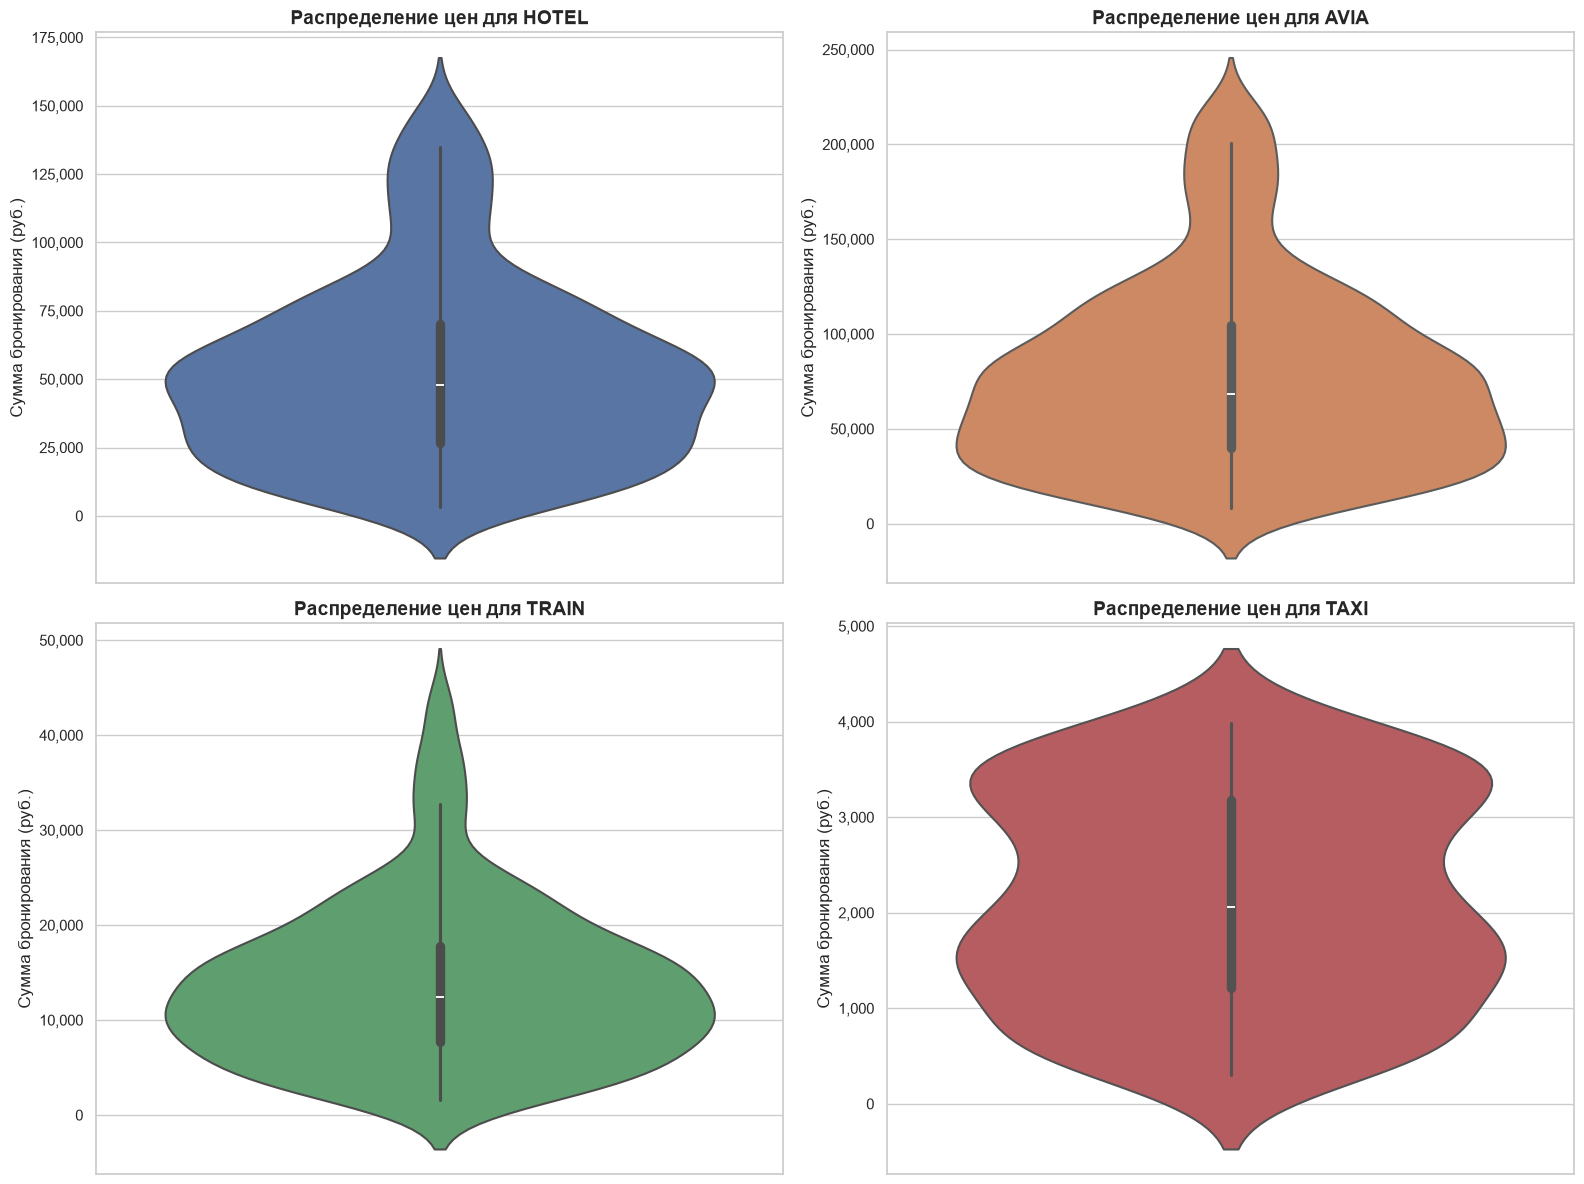

In [25]:
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten() 

products = ['hotel', 'avia', 'train', 'taxi']
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

for i, product in enumerate(products):

    prod_data = bookings[bookings['subproduct'] == product]

   
    sns.violinplot(
        data=prod_data,
        y='amount_rub',
        ax=axes[i],
        color=colors[i],
        inner='box',
        linewidth=1.5
    )


    axes[i].set_title(
        f'Распределение цен для {product.upper()}',
        fontsize=14,
        fontweight='bold'
    )
    axes[i].set_ylabel('Сумма бронирования (руб.)', fontsize=12)
    axes[i].set_xlabel('')


    axes[i].yaxis.set_major_formatter(
        plt.FuncFormatter(lambda x, loc: f'{int(x):,}')
    )


plt.tight_layout()
plt.show()


симметрично только распределение такси, все остальные скошены сильно выбросами

In [26]:

heavy_trains = bookings[
    (bookings['subproduct'] == 'train') &
    (bookings['status'] == 'confirmed') &
    (bookings['amount_rub'] >= 30000)
].copy()



heavy_trains['days_to_trip'] = (heavy_trains['trip_date'] - heavy_trains['booking_date']).dt.days


heavy_trains_report = heavy_trains.merge(
    clients[['client_id', 'company_name', 'tier', 'industry']],
    on='client_id',
    how='left'
)

heavy_trains_report = heavy_trains_report.sort_values(by='amount_rub', ascending=False).reset_index(drop=True)

print(f' Найдено подозрительно дорогих ж/д билетов (>= 30k руб.): {len(heavy_trains_report)} шт.')
print(f' Общая сумма аномальных ж/д бронирований: {heavy_trains_report['amount_rub'].sum():,.2f} руб.\n')

heavy_trains_report[
    [
        'booking_id',
        'company_name',
        'tier',
        'city_from',
        'city_to',
        'amount_rub',
        'days_to_trip'
    ]
]


 Найдено подозрительно дорогих ж/д билетов (>= 30k руб.): 22 шт.
 Общая сумма аномальных ж/д бронирований: 798,888.92 руб.



,booking_id,company_name,tier,city_from,city_to,amount_rub,days_to_trip
0,1702,ЮгКомпани,1,Москва,Екатеринбург,43921.34,13
1,1957,ПсиЦифровой,1,Москва,Санкт-Петербург,43506.21,21
2,1790,ТауКонсалтинг,1,Новосибирск,Уфа,43478.56,12
3,723,ТауКонсалтинг,1,Сочи,Екатеринбург,42056.94,21
4,1356,ПсиЦифровой,1,Уфа,Екатеринбург,41334.43,11
5,1905,ПсиЦифровой,1,Новосибирск,Уфа,38926.95,18
6,998,ГаммаЭкспресс,1,Сочи,Уфа,37224.86,2
7,476,ТауКонсалтинг,1,Уфа,Москва,37113.36,21
8,85,ЮгКомпани,1,Екатеринбург,Новосибирск,37079.70,5
9,459,ТауКонсалтинг,1,Санкт-Петербург,Москва,36977.92,21


все эти дорогие ж\д билеты брали клиенты тир 1, возможно они выкупали всё купе или брали вип места на сапсане, поэто я принял решение эти выбросы не удалять.

проверка на наличие 'заглушек' в данных

In [27]:
text_placeholders = ['unknown', 'null', 'none', '-', '', '0', '1900-01-01', '0000-00-00']

for col in bookings.columns:
    if bookings[col].dtype == 'str':
        lowered_ser = bookings[col].astype(str).str.strip().str.lower()
        found_placeholders = bookings[bookings[col].astype(str).str.strip().str.lower().isin(text_placeholders)][col].unique()
        if len(found_placeholders) > 0:
            print(col, f' Найдены скрытые заглушки: {found_placeholders}')
            
    if col == 'status':
        invalid_statuses = set(bookings['status'].dropna().unique()) - {'confirmed', 'cancelled'}
        if invalid_statuses:
            print(f'status  Некорректные статусы: {invalid_statuses}')
            
    if col == 'subproduct':
        invalid_products = set(bookings['subproduct'].dropna().unique()) - {'hotel', 'avia', 'train', 'taxi'}
        if invalid_products:
            print(f'subproduct  Некорректные типы продуктов: {invalid_products}')

    if col == 'booking_id':
        if not bookings['booking_id'].is_unique:
            duplicated_ids = bookings[bookings['booking_id'].duplicated()]['booking_id'].unique()
            print(f'booking_id  Обнаружены дубликаты ID бронирования! Примеры: {duplicated_ids[:5]}')


проверка клиентов на аномальные поездки

аномалией будем считать 2 и более поездки в разные города или из разных городов совершённые одним клиентом в один день, что физически невозможно сделать

In [28]:

transport = bookings[
    (bookings["subproduct"].isin(["avia", "train"])) &
    (bookings["status"] == "confirmed")
].copy()


# Функция для проверки каждого клиента в конкретный день
def check_day_anomaly(group):
    # Если поездка всего одна, она нам не интересна
    if len(group) < 2:
        return False
        
    # Собираем все города отправления и назначения за этот день
    all_from = set(group["city_from"])
    all_to = set(group["city_to"])
    

    all_cities = all_from.union(all_to)
    
    # ЛОГИЧЕСКОЕ ПРАВИЛО СТЫКОВКИ:
    # Если это нормальный транзит из N поездок (например, 2 поездки: Казань->Сочи, Сочи->СПб),
    # то всего уникальных городов должно быть ровно N + 1 (в данном случае 3: Казань, Сочи, СПб).
    # Если городов больше, чем N + 1, значит цепочка разорвана (две параллельные поездки).
    if len(all_cities) > (len(group) + 1):
        return True
        
    # ДОПОЛНИТЕЛЬНОЕ ПРАВИЛО (на случай ложного кругового транзита А->Б и Б->А в один день):
    # Если человек успел вернуться обратно - это физически возможно (например, слетал на встречу), иначе это точно аномалия:
    if not all_from.intersection(all_to) and len(group) >= 2:
        return True
        
    return False

 

suspicious_indices = (
    transport
    .groupby(["client_id", "trip_date"])
    .filter(check_day_anomaly)
)


result = suspicious_indices.sort_values(
    ["client_id", "trip_date", "booking_date"]
).reset_index(drop=True)


result[
    [
        "client_id",
        "trip_date",
        "booking_id",
        "subproduct",
        "city_from",
        "city_to",
        "amount_rub",
        "status"
    ]
]



,client_id,trip_date,booking_id,subproduct,city_from,city_to,amount_rub,status
0,1,2025-03-20,367,avia,Москва,Новосибирск,43176.98,confirmed
1,1,2025-03-20,736,train,Уфа,Санкт-Петербург,3682.84,confirmed
2,1,2025-08-26,1015,avia,Уфа,Сочи,88762.01,confirmed
3,1,2025-08-26,200,avia,Новосибирск,Сочи,40616.78,confirmed
4,4,2025-06-29,1692,avia,Екатеринбург,Сочи,87786.82,confirmed
...,...,...,...,...,...,...,...,...
71,45,2025-05-07,1236,avia,Уфа,Сочи,27325.68,confirmed
72,45,2025-05-23,1602,avia,Новосибирск,Казань,35345.59,confirmed
73,45,2025-05-23,649,train,Санкт-Петербург,Казань,10565.33,confirmed
74,49,2025-03-19,1755,avia,Уфа,Екатеринбург,18334.87,confirmed


проверка на распределённость этих поездок по клиентам, тем самым мы отличим ошибку в записи данных одного клиента от общей системной ошибки в записи данных

In [29]:
print(result['client_id'].value_counts().head(10))

client_id
23    13
37     7
4      6
27     6
45     6
1      4
10     4
19     4
21     4
29     4
Name: count, dtype: int64


мною было принято решение удалить аномальные поездки клиентов, так как их всего 76 штук, что не очень критично по сравнению со всеми данными, а также они бы рабтали как лишний шум при вычислении необходимых метрик, что могло бы повлиять на выводы анализа в последующем

In [30]:
fraud_ids = result['booking_id'].unique()
bookings_clean = bookings[~bookings['booking_id'].isin(fraud_ids)].copy()


bookings_clean['month'] = bookings_clean['booking_date'].dt.to_period('M')


print(f"Было строк в исходном датасете: {len(bookings)}")
print(f"Осталось строк после удаления накладок: {len(bookings_clean)}")
print(f"Удалено ошибочных бронирований: {len(bookings) - len(bookings_clean)}")


Было строк в исходном датасете: 1964
Осталось строк после удаления накладок: 1888
Удалено ошибочных бронирований: 76


**Итоги EDA:**
 - были найдены и удалены аномальные бронирования клиентов
 - была найдена и исправлена ошибка в несоответствии типов данных в таблице и справки к ней
 - распределение цен у субпродуктов скошено вправо, за исключением такси, это стоит принять во внимание при выборе меры центральной тенденции и стат. критериев в последующем

 в остальном данные готовы к анализу

**Задание 1.** Рассчитай GMV и количество бронирований (`confirmed`) по каждому субпродукту помесячно за 2025 год. Ответь: какой субпродукт генерирует наибольший оборот и есть ли явная сезонность?

In [31]:
final_stats = bookings_clean[(bookings_clean['status'] == 'confirmed') & (bookings_clean["booking_date"].dt.year == 2025)]
final_stats = final_stats.groupby(['month', 'subproduct']).agg(GMV=('amount_rub', 'sum'), booking_count = ('booking_id', 'count')).reset_index()

In [32]:
n_before = len(bookings_clean)

not_confirmed = (bookings_clean['status'] != 'confirmed')
n_not_confirmed = not_confirmed.sum()

confirmed = bookings_clean[bookings_clean['status'] == 'confirmed']
wrong_year = confirmed['booking_date'].dt.year != 2025
n_wrong_year = wrong_year.sum()

print('Всего строк:', n_before)
print('Ушло из-за статуса:', n_not_confirmed)
print('Ушло из-за года (среди confirmed):', n_wrong_year)
print('Сумма ушедших:', n_not_confirmed + n_wrong_year)

print('NaN в status:', bookings_clean['status'].isna().sum())
print('NaN в booking_date:', bookings_clean['booking_date'].isna().sum())

print(bookings_clean['status'].value_counts())

Всего строк: 1888
Ушло из-за статуса: 273
Ушло из-за года (среди confirmed): 0
Сумма ушедших: 273
NaN в status: 0
NaN в booking_date: 0
status
confirmed    1615
cancelled     273
Name: count, dtype: int64


In [33]:

total_gmv_per_product = (
    bookings_clean
    .groupby("subproduct")["amount_rub"]
    .sum()
    .sort_values(ascending=False)
    .reset_index(name="total_gmv")
)


total_gmv_per_product["share_%"] = (total_gmv_per_product["total_gmv"] / total_gmv_per_product["total_gmv"].sum()) * 100

print(" ДОЛИ СУБПРОДУКТОВ В ОБЩЕМ ОБОРОТЕ (GMV):")
print(total_gmv_per_product)


 ДОЛИ СУБПРОДУКТОВ В ОБЩЕМ ОБОРОТЕ (GMV):
  subproduct    total_gmv    share_%
0       avia  55427018.67  59.342173
1      hotel  32715423.35  35.026317
2      train   4841816.46   5.183824
3       taxi    418149.53   0.447686


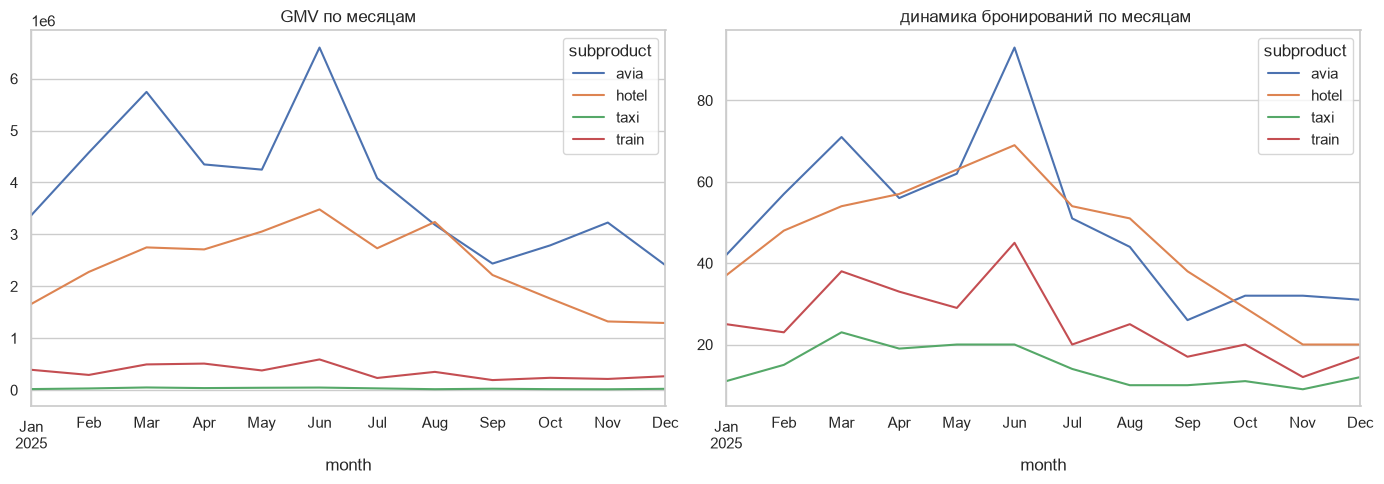

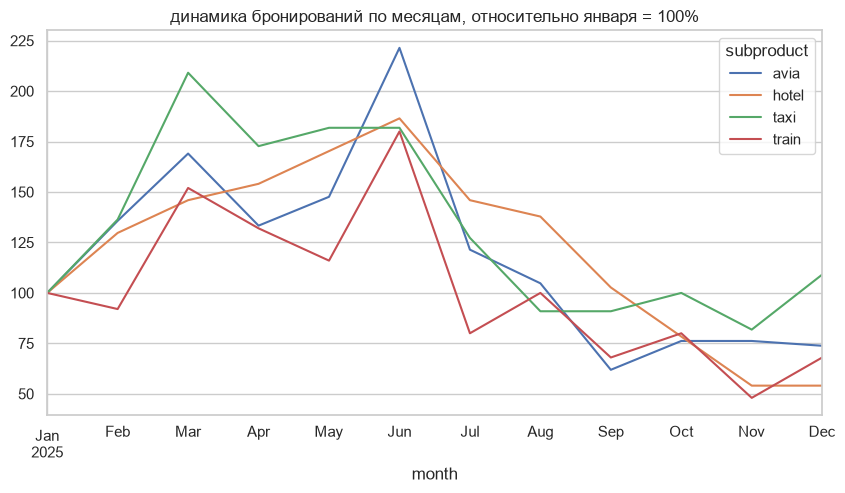

subproduct   avia  hotel   taxi  train
month                                 
2025-01     100.0  100.0  100.0  100.0
2025-02     135.7  129.7  136.4   92.0
2025-03     169.0  145.9  209.1  152.0
2025-04     133.3  154.1  172.7  132.0
2025-05     147.6  170.3  181.8  116.0
2025-06     221.4  186.5  181.8  180.0
2025-07     121.4  145.9  127.3   80.0
2025-08     104.8  137.8   90.9  100.0
2025-09      61.9  102.7   90.9   68.0
2025-10      76.2   78.4  100.0   80.0
2025-11      76.2   54.1   81.8   48.0
2025-12      73.8   54.1  109.1   68.0


In [34]:
pivot_count = final_stats.pivot(index='month', columns='subproduct', values='booking_count')
pivot_gmv = final_stats.pivot(index='month', columns='subproduct', values='GMV')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pivot_gmv.plot(ax=axes[0], title='GMV по месяцам')
pivot_count.plot(ax=axes[1], title=' динамика бронирований по месяцам')
plt.tight_layout()
plt.show()

pivot_count_idx = pivot_count.div(pivot_count.iloc[0]) * 100
pivot_count_idx.plot(figsize=(10,5), title='динамика бронирований по месяцам, относительно января = 100%')
plt.show()

print(pivot_count_idx.round(1))

In [35]:
final_stats['share_total'] = final_stats.groupby('month')['GMV'].transform(lambda x: x / x.sum())

aug = final_stats[final_stats['month'] == '2025-08'].sort_values('GMV', ascending=False)
print(aug[['subproduct', 'GMV', 'share_total']])

avia_share = final_stats[final_stats['subproduct'] == 'avia'][['month', 'share_total']]
print(avia_share)

   subproduct         GMV  share_total
29      hotel  3238339.59     0.476881
28       avia  3184410.05     0.468939
31      train   350742.13     0.051651
30       taxi    17173.34     0.002529
      month  share_total
0   2025-01     0.619426
4   2025-02     0.637702
8   2025-03     0.635591
12  2025-04     0.571561
16  2025-05     0.549863
20  2025-06     0.615641
24  2025-07     0.576530
28  2025-08     0.468939
32  2025-09     0.500129
36  2025-10     0.580171
40  2025-11     0.675236
44  2025-12     0.602846


изменение среднего чека по месяцам у субпродуктов

In [36]:
final_stats['avg_check'] = final_stats['GMV'] / final_stats['booking_count']
avg_check_pivot = final_stats.pivot(index='month', columns='subproduct', values='avg_check')
print(avg_check_pivot.round(0))

for col in avg_check_pivot.columns:
    y = avg_check_pivot[col].values
    x = np.arange(len(y))
    slope = np.polyfit(x, y, 1)[0]
    print(col, 'наклон тренда чека (₽/мес):', round(slope, 1))

subproduct      avia    hotel    taxi    train
month                                         
2025-01      80166.0  44821.0  1756.0  15639.0
2025-02      80295.0  47434.0  2096.0  12693.0
2025-03      80912.0  50903.0  2197.0  13011.0
2025-04      77634.0  47545.0  2022.0  15465.0
2025-05      68507.0  48485.0  2229.0  13034.0
2025-06      70962.0  50450.0  2434.0  13121.0
2025-07      80042.0  50601.0  2340.0  11660.0
2025-08      72373.0  63497.0  1717.0  14030.0
2025-09      93743.0  58342.0  2623.0  11343.0
2025-10      87127.0  60800.0  1630.0  11820.0
2025-11     100865.0  66107.0  1742.0  17881.0
2025-12      77559.0  64634.0  2026.0  15705.0
avia наклон тренда чека (₽/мес): 1053.1
hotel наклон тренда чека (₽/мес): 1938.6
taxi наклон тренда чека (₽/мес): -9.9
train наклон тренда чека (₽/мес): 69.9


смотрим на изменчивость данных по количеству бронирований и GMV, по субпродуктам(коэфициент вариации CV) и max/min значения

In [37]:
season_count = pivot_count.agg(['max', 'min', 'mean', 'std']).T
season_count['max/min'] = season_count['max'] / season_count['min']
season_count['CV_%'] = season_count['std'] / season_count['mean'] * 100
print(season_count[['max', 'min', 'max/min', 'CV_%']].round(2))

season_gmv = pivot_gmv.agg(['max', 'min', 'mean', 'std']).T
season_gmv['max/min'] = season_gmv['max'] / season_gmv['min']
season_gmv['CV_%'] = season_gmv['std'] / season_gmv['mean'] * 100
print(season_gmv[['max', 'min', 'max/min', 'CV_%']].round(2))

             max   min  max/min   CV_%
subproduct                            
avia        93.0  26.0     3.58  39.30
hotel       69.0  20.0     3.45  35.89
taxi        23.0   9.0     2.56  33.21
train       45.0  12.0     3.75  37.61
                   max         min  max/min   CV_%
subproduct                                        
avia        6599484.46  2404330.46     2.74  32.98
hotel       3481068.91  1292673.56     2.69  31.13
taxi          50531.45    15674.72     3.22  41.07
train        590464.31   192824.64     3.06  37.64


так как данные скошенные по ценам у субпродуктов коэфициент вариации стоит расчитать разными методами для проверки 

In [38]:
def compute_variants(df, label):
    print(f'=== {label} ===')
    for col in df.columns:
        vals = df[col].values
        mean_, median_, std_ = vals.mean(), np.median(vals), vals.std()
        q1, q3 = np.percentile(vals, [25, 75])
        cv_mean = std_ / mean_ * 100
        cv_median_denom = std_ / median_ * 100
        mad = np.median(np.abs(vals - median_))
        robust_cv = mad / median_ * 1.4826 * 100
        quartile_cv = (q3 - q1) / (q3 + q1) * 100
        print(f'{col:8s} skew={skew(vals):+.2f}  CV(mean)={cv_mean:5.1f}  '
              f'CV(std/median)={cv_median_denom:5.1f}  robustCV(MAD)={robust_cv:5.1f}  '
              f'quartileCV={quartile_cv:5.1f}')

compute_variants(pivot_count, 'count')
compute_variants(pivot_gmv, 'GMV')

=== count ===
avia     skew=+0.78  CV(mean)= 37.6  CV(std/median)= 39.4  robustCV(MAD)= 46.8  quartileCV= 29.1
hotel    skew=-0.30  CV(mean)= 34.4  CV(std/median)= 31.2  robustCV(MAD)= 35.9  quartileCV= 22.0
taxi     skew=+0.50  CV(mean)= 31.8  CV(std/median)= 35.5  robustCV(MAD)= 34.2  quartileCV= 28.3
train    skew=+0.69  CV(mean)= 36.0  CV(std/median)= 38.0  robustCV(MAD)= 37.1  quartileCV= 21.8
=== GMV ===
avia     skew=+0.74  CV(mean)= 31.6  CV(std/median)= 33.2  robustCV(MAD)= 29.4  quartileCV= 17.6
hotel    skew=-0.14  CV(mean)= 29.8  CV(std/median)= 28.4  robustCV(MAD)= 38.4  quartileCV= 23.9
taxi     skew=+0.36  CV(mean)= 39.3  CV(std/median)= 41.7  robustCV(MAD)= 52.7  quartileCV= 35.6
train    skew=+0.57  CV(mean)= 36.0  CV(std/median)= 38.8  robustCV(MAD)= 39.9  quartileCV= 27.8


Коэффициент вариации считался четырьмя способами (класический по определению CV=std/mean, CV с медианой в знаменателе, робастный CV на основе MAD, и с помощью квантилей), так как на 12 точках оценка среднего и стандартного отклонения чувствительна к выбросам. Ранжирование устойчиво по краям: по количеству броней стабильно **самый волатильный субпродукт - avia (CV 29-47% в зависимости от метода)**, **по GMV - стабильно taxi (CV 36-53%)**. Середина рейтинга неустойчива к выбору метрики: например, hotel по GMV - наименее волатильный при расчёте через mean (29.8%), но второй по волатильности при робастном расчёте через MAD (38.4%), поэтому точное место hotel в рейтинге не утверждается. 

Отмечу также, что оценка skewness на 12 месячных точках сама по себе шумная (0.14–0.78) и является скорее указанием на возможную асимметрию, чем строгим доказательством.

In [39]:
pct_change = (pivot_count.loc['2025-09'] / pivot_count.loc['2025-08'] - 1) * 100
print(pct_change.round(1))

subproduct
avia    -40.9
hotel   -25.5
taxi      0.0
train   -32.0
dtype: float64


просадка с августа по сентябрь наблюдается у всех субпродуктов

In [40]:
june = bookings_clean[
    (bookings_clean['status'] == 'confirmed') &
    (bookings_clean['booking_date'].dt.year == 2025) &
    (bookings_clean['month'] == '2025-06')
]
print(june.groupby('client_id')['amount_rub'].sum().sort_values(ascending=False).head(10))
print('Доля топ-1 клиента в июне:', june.groupby('client_id')['amount_rub'].sum().max() / june['amount_rub'].sum())

client_id
19    1072415.92
33     638104.71
27     609086.33
45     603047.50
21     586976.93
49     544106.16
23     519991.74
46     466494.55
15     449495.00
47     445879.56
Name: amount_rub, dtype: float64
Доля топ-1 клиента в июне: 0.10004157027488689


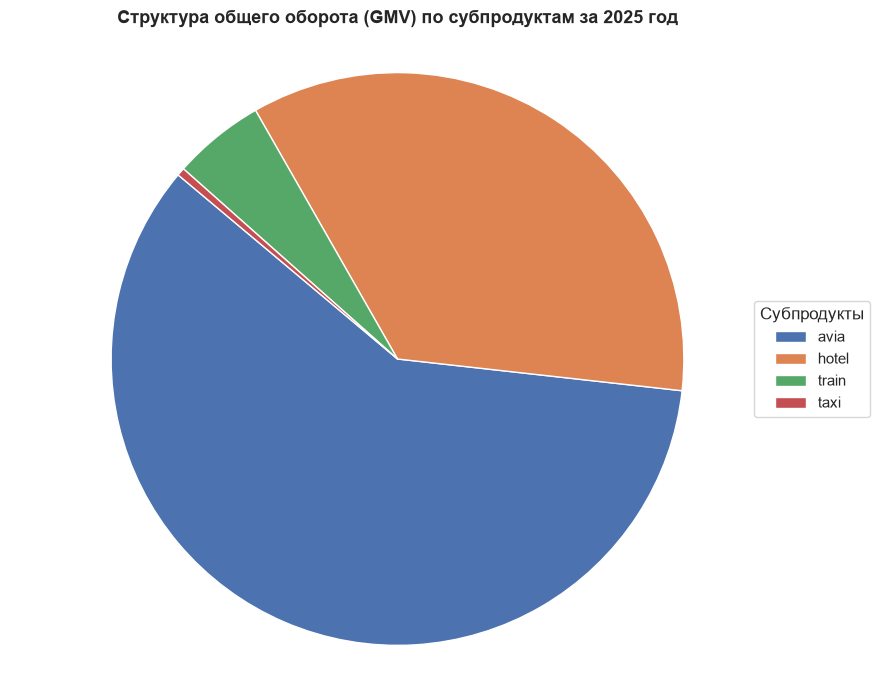

In [41]:
plt.figure(figsize=(9, 7))


wedges, texts = plt.pie(
    total_gmv_per_product["total_gmv"],
    startangle=140,
    colors=["#4C72B0", "#DD8452", "#55A868", "#C44E52"]
)


plt.legend(
    wedges,
    total_gmv_per_product["subproduct"],
    title="Субпродукты",
    loc="center left",
    bbox_to_anchor=(0.95, 0.5), 
    fontsize=11,
)


plt.title(
    "Структура общего оборота (GMV) по субпродуктам за 2025 год",
    fontsize=13,
    fontweight="bold",
    pad=15,
)

plt.axis("equal")
plt.tight_layout()
plt.show()


**Вывод по первому заданию:**

По итогам 2025 года лидер по GMV - avia (59.3% годового оборота), лидерство устойчиво держится 11 из 12 месяцев (доля 55-68%), кроме августа, когда доля avia падает до минимума за год - 46.9%, и hotel временно выходит вперёд (47.7% против 46.9%, разница 53.9К ₽) - единственный месяц смены лидера; 

по количеству броней avia лидирует весь год без исключений. 

Пик активности по всем субпродуктам приходится на июнь (у avia - 221% от января; проверка показала, что пик распределён по клиентам, топ-1 клиент даёт лишь 10% июньского GMV, то есть это не разовый выброс, а скорее системный сезонный эффект), после чего идёт устойчивое снижение к декабрю. 

Рост доли hotel в августе связан не с числом сделок, а с ростом среднего чека: у hotel тренд чека +1938.6 ₽/мес (рост с 44.8К до 64.6К за год) - самый выраженный из всех субпродуктов, у avia/train/taxi заметного тренда чека нет. 

Сезонность выражена количественно, но неоднородно по разным метрикам: по числу броней сильнее всего колеблются train (CV 37.6%) и avia (CV 39.3%), а по деньгам - taxi (CV 41.1%) и train (CV 37.6%), то есть taxi волатилен по выручке, но стабилен по количеству сделок, а avia - наоборот; при переходе с август по сентябрь синхронно просели три из четырёх субпродуктов (avia -40.9%, hotel -25.5%, train -32.0%), кроме taxi (0%), что говорит скорее об общем сезонном факторе, чем о случайности. 
 

Так как выводы построены на данных одного года, поэтому сезонность - это пока лишь гипотеза на основе внутригодовой цикличности, для её подтверждения требуются данные за несколько лет минимум.

**Задание 2.** Найди топ-10 клиентов по GMV за весь 2025 год. Для каждого покажи: GMV, количество бронирований, средний чек, тир клиента, отрасль.

In [42]:
clients_statistics = bookings_clean[bookings_clean['status'] == 'confirmed']

clients_statistics = clients_statistics.groupby('client_id').agg(GMV = ('amount_rub', 'sum'), count_booking = ('booking_id', 'count')).reset_index()

clients_statistics['AOV'] = clients_statistics['GMV'] / clients_statistics['count_booking']


clients_statistics = clients_statistics.merge(clients[['client_id', 'tier', 'industry']],
    on="client_id",
    how="inner")

clients_statistics = clients_statistics.sort_values(by='GMV', ascending=False).head(10)

clients_statistics[['client_id','GMV','count_booking','AOV','tier','industry']]

,client_id,GMV,count_booking,AOV,tier,industry
26,27,10011920.18,125,80095.361440,1,IT
22,23,7963961.90,102,78078.057843,1,IT
18,19,7614112.57,94,81001.197553,1,Строительство
32,33,7243077.04,83,87265.988434,1,Строительство
0,1,3442329.10,66,52156.501515,2,Финансы
16,17,2761935.30,61,45277.627869,2,Логистика
20,21,2572061.58,60,42867.693000,2,Финансы
33,34,2553293.58,56,45594.528214,2,Логистика
44,45,2394653.25,56,42761.665179,2,Ритейл
36,37,2342553.57,56,41831.313750,2,Логистика


дополнительно к блоку 7

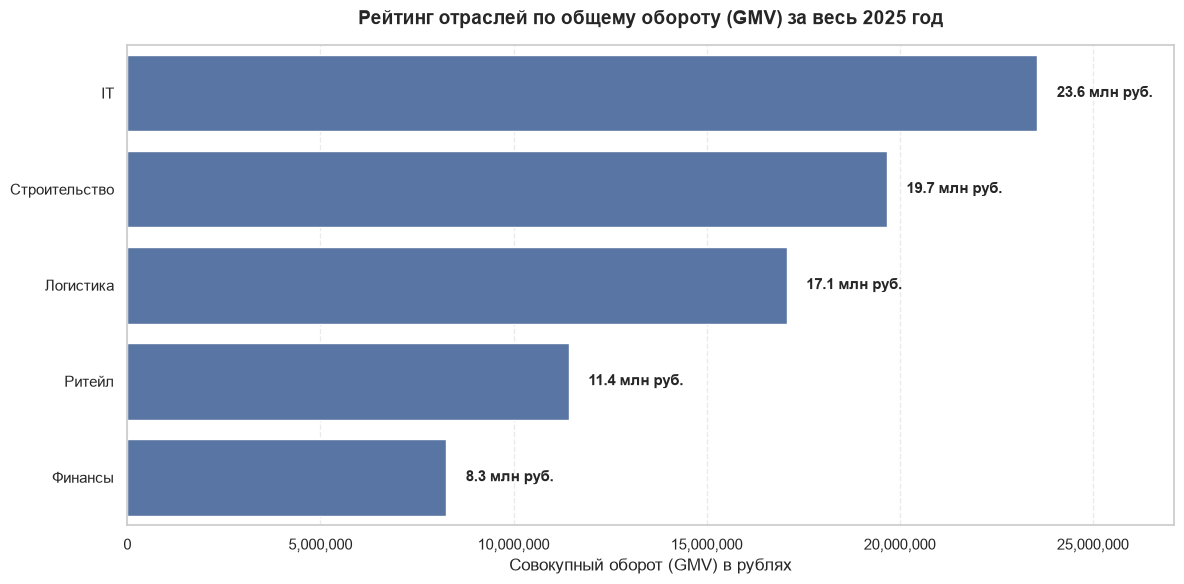

In [43]:
total_industry = bookings_clean[bookings_clean['status'] == 'confirmed'].merge(
    clients[['client_id', 'industry']], on='client_id', how='inner'
)

industry_year = (
    total_industry.groupby('industry')['amount_rub']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)


plt.figure(figsize=(12, 6))

sns.barplot(
    data=industry_year,
    x='amount_rub',
    y='industry'  
)


for index, row in industry_year.iterrows():
    plt.text(
        row['amount_rub'] + 500000,  
        index,
        f'{row['amount_rub']/1e6:.1f} млн руб.',
        va="center",
        fontsize=11,
        fontweight='bold'
    )


plt.title(
    'Рейтинг отраслей по общему обороту (GMV) за весь 2025 год',
    fontsize=14,
    fontweight='bold',
    pad=15
)
plt.xlabel('Совокупный оборот (GMV) в рублях', fontsize=12)

plt.ylabel('')

plt.xlim(0, industry_year['amount_rub'].max() * 1.15)


plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, loc: f"{int(x):,}")
)
plt.grid(True, linestyle="--", alpha=0.4, axis="x")
plt.tight_layout()
plt.show()

**Почему выбран этот тип графика и этот разрез:**

**Тип графика (Горизонтальная гистограмма с сортировкой):** Это лучший тип визуализации для сравнения итоговых категориальных данных. Горизонтальная ориентация позволяет легко и без сокращений читать названия отраслей. Сортировка столбцов сверху вниз (от большего к меньшему) мгновенно формирует внятный рейтинг и распределяет роли: сразу видно лидеров, средний класс и аутсайдеров по объему сгенерированной выручки. Текстовые подписи прямо на столбцах позволяют избавиться от необходимости всматриваться в шкалу.

**Разрез (Итоговые отрасли за год):** Закрывает верхнеуровневый вопрос стратегического планирования: «Кто наш ключевой клиент на макроуровне?». Этот разрез показывает, на какие сферы бизнеса коммерческому отделу нужно делать упор при продажах и поиске новых партнеров в следующем году, а какие отрасли пока не приносят ощутимого дохода.

**Задание 3.** Посчитай долю отмен (`cancelled / всего`) по субпродуктам. Укажи, если есть субпродукт с заметно более высокой долей отмен, и предложи гипотезу - почему.

In [44]:
crosstab = pd.crosstab(
    bookings_clean["subproduct"],
    bookings_clean["status"],
    normalize="index",
) * 100
print(crosstab)

status      cancelled  confirmed
subproduct                      
avia        16.386555  83.613445
hotel       13.322632  86.677368
taxi        10.769231  89.230769
train       14.606742  85.393258


Явной аномалии среди этих данных нет. Все четыре категории укладываются в стандартный для туристического B2B-рынка диапазон отмен от 10% до 17%, однако если выделять лидера, то avia (авиабилеты) имеет заметно более высокую долю отмен (16.4%) на фоне остальных услуг, возможно это связано с частыми отменами рейсов из-за СВО и опасности в воздухе

### Блок 2 — Бизнес-анализ 

**Задание 4.** Есть гипотеза: клиенты тира 1 бронируют более дорогие продукты, но реже, чем клиенты тира 3. Проверь гипотезу данными. Подтвердилась ли она? Что ещё интересного ты заметил(-а) при анализе тиров?



In [45]:
tier_analysis = bookings_clean[bookings_clean['status'] == 'confirmed'].merge(clients[['client_id', 'tier']])
tier_analysis = (
    tier_analysis.groupby("tier")
    .agg(
        total_gmv=("amount_rub", "sum"),
        total_bookings=("booking_id", "count"),
        unique_clients=("client_id", "nunique")  
    )
    .reset_index()
)


tier_analysis["avg_check_per_booking"] = (
    tier_analysis["total_gmv"] / tier_analysis["total_bookings"]
)

tier_analysis["bookings_per_client"] = (
    tier_analysis["total_bookings"] / tier_analysis["unique_clients"]
)

tier_analysis[
    [
        "tier",
        "avg_check_per_booking",
        "unique_clients",
        "total_bookings",
        "bookings_per_client",
    ]
]

,tier,avg_check_per_booking,unique_clients,total_bookings,bookings_per_client
0,1,81269.979431,4,404,101.000000
1,2,44484.692084,16,787,49.187500
2,3,28721.102335,30,424,14.133333


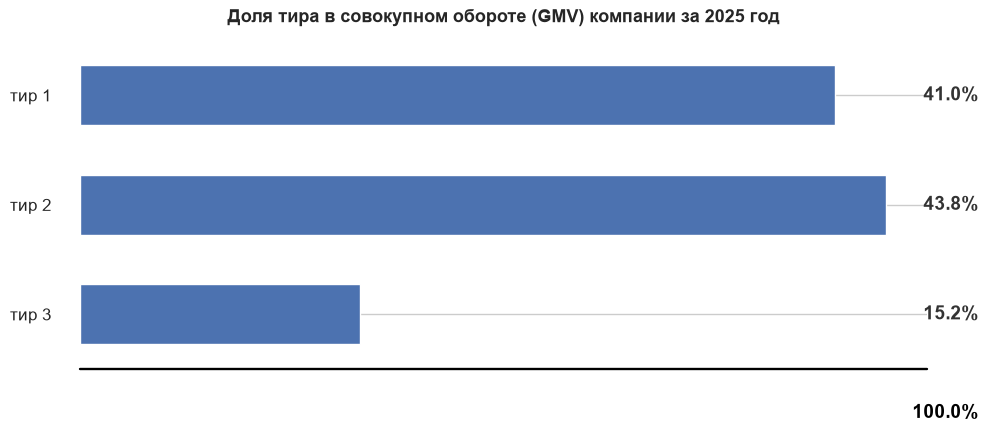

In [46]:
tiers_labels = ['тир 1', 'тир 2', 'тир 3']
shares = [41.0, 43.8, 15.2]


tiers_labels = tiers_labels[::-1]
shares = shares[::-1]

fig, ax = plt.subplots(figsize=(10, 4.5))


bars = ax.barh(tiers_labels, shares, color='#4C72B0', height=0.55)


x_pos = max(shares) + 5

for bar, share in zip(bars, shares):
    ax.text(
        x_pos,
        bar.get_y() + bar.get_height() / 2,
        f'{share:.1f}%',
        va='center',
        ha='right',  
        fontsize=14,
        fontweight='bold',
        color='#333333'
    )


ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.xaxis.set_visible(False)  


ax.tick_params(axis='y', left=False, labelsize=12, pad=15)


ax.axhline(y=-0.5, color="#000000", linewidth=1.7, clip_on=False)


ax.text(
    x_pos,
    -0.9,  
    '100.0%',
    va='center',
    ha='right',
    fontsize=14,
    fontweight='bold',
    color='#000000'
)


plt.title(
    'Доля тира в совокупном обороте (GMV) компании за 2025 год',
    fontsize=13,
    fontweight='bold',
    pad=20,
    loc='center'
)

plt.tight_layout()
plt.show()



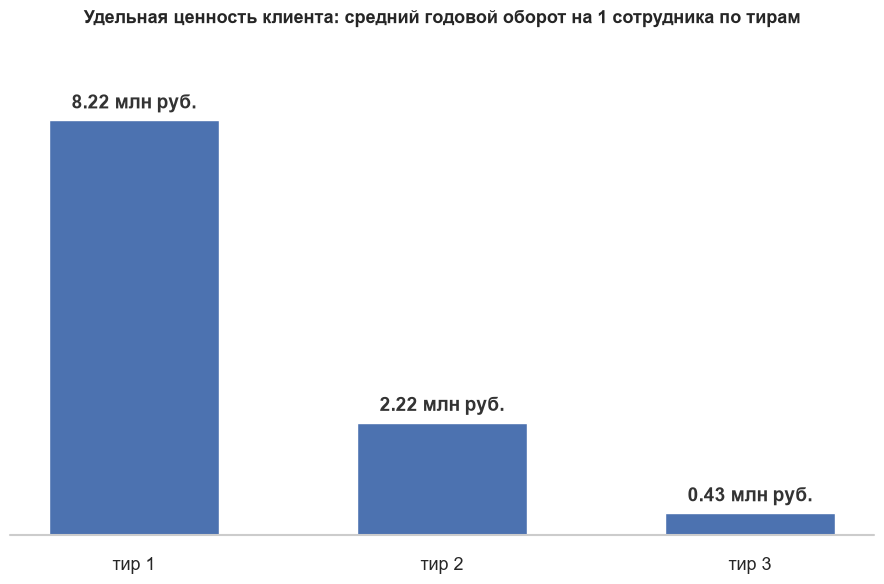

In [47]:
tiers_labels = ['тир 1', 'тир 2', 'тир 3']
values_per_client = [8224250.00, 2224250.00, 430815.00] 

fig, ax = plt.subplots(figsize=(9, 6))


bars = ax.bar(tiers_labels, values_per_client, color='#4C72B0', width=0.55)


for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 150000, 
        f'{height/1e6:.2f} млн руб.',
        ha='center',
        va='bottom',
        fontsize=14, 
        fontweight='bold',
        color='#333333'
    )


ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.yaxis.set_visible(False) 

ax.grid(False)

ax.tick_params(axis='x', bottom=False, labelsize=13, pad=10)


ax.axhline(y=0, color='#CCCCCC', linewidth=1.5, clip_on=False)


ax.set_ylim(0, max(values_per_client) * 1.15)

plt.title(
    'Удельная ценность клиента: средний годовой оборот на 1 сотрудника по тирам',
    fontsize=13,
    fontweight='bold',
    pad=25,
    loc='center'
)

plt.tight_layout()
plt.show()

**Задание 5.** Найди клиентов, у которых в первом полугодии 2025 года (январь–июнь) были бронирования, а во втором (июль–декабрь) — не было ни одного подтверждённого. Это потенциальный отток (churn). Сколько таких клиентов? Каков их суммарный GMV за H1? Какого они тира?


In [48]:

bookings_half = bookings_clean[
    (bookings_clean['status'] == 'confirmed') &
    (bookings_clean['booking_date'].dt.year == 2025)
].copy()
bookings_half['month_num'] = bookings_half['booking_date'].dt.month
bookings_half['H'] = np.where(bookings_half['month_num'] <= 6, 'H1', 'H2')

h1_ids = set(bookings_half[bookings_half['H'] == 'H1']['client_id'])
h2_ids = set(bookings_half[bookings_half['H'] == 'H2']['client_id'])
churn_ids = h1_ids - h2_ids

print('Клиентов с confirmed в H1:', len(h1_ids))
print('Клиентов с confirmed в H2:', len(h2_ids))
print('Churn (были в H1, нет в H2):', len(churn_ids))

churn_h1 = bookings_half[(bookings_half['H'] == 'H1') & (bookings_half['client_id'].isin(churn_ids))]
churn_gmv_h1 = churn_h1['amount_rub'].sum()
total_gmv_h1 = bookings_half[bookings_half['H'] == 'H1']['amount_rub'].sum()

print('Суммарный GMV churn-клиентов за H1:', round(churn_gmv_h1, 2))
print('Доля этого GMV в общем GMV H1:', round(churn_gmv_h1 / total_gmv_h1 * 100, 1), '%')
print('Доля churn-клиентов от всех клиентов с H1-активностью:', 
      round(len(churn_ids) / len(h1_ids) * 100, 1), '%')

churn_df = clients[clients['client_id'].isin(churn_ids)].copy()
churn_df['gmv_h1'] = churn_df['client_id'].map(churn_h1.groupby('client_id')['amount_rub'].sum())
churn_df['cnt_h1'] = churn_df['client_id'].map(churn_h1.groupby('client_id')['booking_id'].count())

print('\nРаспределение churn по tier:')
print(churn_df['tier'].value_counts().sort_index())

print('\nПо клиентам (по убыванию GMV H1):')
print(churn_df[['client_id','company_name','tier','industry','gmv_h1','cnt_h1']]
      .sort_values('gmv_h1', ascending=False))

Клиентов с confirmed в H1: 50
Клиентов с confirmed в H2: 34
Churn (были в H1, нет в H2): 16
Суммарный GMV churn-клиентов за H1: 16773521.15
Доля этого GMV в общем GMV H1: 35.2 %
Доля churn-клиентов от всех клиентов с H1-активностью: 32.0 %

Распределение churn по tier:
tier
2     6
3    10
Name: count, dtype: int64

По клиентам (по убыванию GMV H1):
    client_id    company_name  tier       industry      gmv_h1  cnt_h1
44         45    СтандартХолд     2         Ритейл  2394653.25      56
36         37       МегаСтрой     2      Логистика  2342553.57      56
47         48     АтлантТрейд     2             IT  2339660.41      51
45         46        НоваяЭра     2      Логистика  2141745.65      41
46         47    ВершинаГрупп     2         Ритейл  1719976.81      42
48         49       ПрофиЛайн     2      Логистика  1710298.63      44
41         42       СинтезПро     3  Строительство   683594.09      21
42         43     АктивБизнес     3         Ритейл   664931.94      19
38       

In [49]:
print('Всего клиентов по tier:')
print(clients['tier'].value_counts().sort_index())

print('\nChurn rate по tier (среди активных в H1):')
tier_counts_h1 = clients[clients['client_id'].isin(h1_ids)]['tier'].value_counts().sort_index()
tier_counts_churn = churn_df['tier'].value_counts().sort_index()
churn_rate_by_tier = (tier_counts_churn / tier_counts_h1 * 100).round(1)
print(churn_rate_by_tier)

Всего клиентов по tier:
tier
1     4
2    16
3    30
Name: count, dtype: int64

Churn rate по tier (среди активных в H1):
tier
1     NaN
2    37.5
3    33.3
Name: count, dtype: float64


In [50]:
top3_churn = churn_df.nlargest(3, 'gmv_h1')['gmv_h1'].sum()
print('Доля топ-3 churn-клиентов в общем churn GMV:', 
      round(top3_churn / churn_gmv_h1 * 100, 1), '%')

Доля топ-3 churn-клиентов в общем churn GMV: 42.2 %


# Вывод по блоку 2:
  1. Гипотеза неподтвердилась, предположение о том, что клиенты Tier 1 бронируют дорогие продукты, но реже, чем Tier 3, оказалось неверным. На самом деле крупные клиенты (Tier 1) лидируют и по цене, и по частоте бронирований. 
     
     Детальный разбор гипотезы:
       
       По цене билета: 
       
       Первая часть подтвердилась. Средний чек одного билета у Tier 1 составляет 81 270 руб., что почти в 3 раза выше, чем у Tier 3 (28 721 руб.).
       
       По частоте бронирований: 
       
       Один сотрудник крупного бизнеса (Tier 1) совершает в среднем 101 бронирований в год (абсолютный лидер), в то время как сотрудник малого бизнеса (Tier 3) бронирует всего 14.1 раз в год.
  
  2.  Аномалии и скрытые инсайты  
        
      Tier 2 (Средний бизнес) - Главный драйвер компании
     
       Эффективность базы: 
       
         Компаний Tier 2 на платформе в два раза меньше, чем мелких (16 против 30), но суммарно они   совершили в 1.8 раза больше бронирований (787 против 424 у Tier 3).
     
       Частота и ценность сотрудника: 
       
         Один сотрудник компании Tier 2 бронирует в 3.5 раза чаще, чем сотрудник Tier 3 (49.2 бронирований против 14.1). 
       
       Ценность (LTV) одного такого клиента колоссальна: 
         
         он приносит сервису около 2.22 млн руб. оборота за год, тогда как клиент малого бизнеса - всего 430 тыс. руб. 
         
         Также я заметил что, несмотря на то, что один VIP-клиент (Tier 1) бьет все рекорды (тратит больше всех на одно бронирование и бронирует чаще всех), суммарно за год средний бизнес (Tier 2) принес сервису больше денег, чем крупный(Tier 2 GMV - около 35.0 млн руб, когда как Tier 1 отстал и принес сервису около 32.8 млн руб.). Произошло это из-за того что крупных VIP-клиентов на платформе критически мало (всего 4 человека), и хотя они «супер-активны», скромный массив из 16 клиентов Tier 2 за счет своего количества перевесил общую чашу весов выручки в свою сторону.
         
  3. Анализ оттока:
      
      Из 50 клиентов компании (все были активны в H1 2025) 16 (32%) не совершили ни одного confirmed-бронирования во втором полугодии. 
      
      Их суммарный GMV за H1 - 16.77 млн ₽ (35.2% от общего H1 GMV), из которых 42.2% сконцентрировано всего в 3 компаниях (СтандартХолд, МегаСтрой, АтлантТрейд). 
      
      Churn rate резко различается по тирам: 
         
         0% в tier 1 (0 из 4 клиентов), против 37.5% в tier 2 (6 из 16) и 33.3% в tier 3 (10 из 30) - при этом разница между tier 2 и tier 3 в пределах статистического шума на такой выборке. 
      
      По объёму денег риск смещён в tier 2: 
         
         6 клиентов дают 12.65 млн ₽ (76% всего churn-GMV) против 4.12 млн у 10 клиентов tier 3.

### Блок 3 — Когортный анализ 

**Задание 6.** «Новый клиент» — тот, у кого `first_booking_date` приходится на 2025 год.

Для каждого нового клиента определи месяц первой активности в 2025 году (когорту). Затем для каждой когорты покажи, сколько клиентов оставались активными в каждом из последующих месяцев (были хотя бы одно `confirmed` бронирование). Это retention-таблица.

Интерпретируй: есть ли когорты, которые удерживаются лучше других?

In [51]:
clients['first_booking_date'].dt.year.value_counts().sort_index()

first_booking_date
2024    50
Name: count, dtype: int64

клиентов совершившие первую покупку в 2025 нет в данных, следоваельно retention-таблица не применима к поставленным условиям задачи

In [52]:
new_clients = bookings_clean.merge(clients, on='client_id', how='inner')
new_clients = new_clients[new_clients['first_booking_date'].dt.year == 2025]
new_clients

,booking_id,client_id,subproduct,booking_date,trip_date,amount_rub,status,city_from,city_to,month,company_name,tier,industry,first_booking_date


### Блок 4 — Визуализация 

**Задание 7.** Построй графики для визуализации других заданий, которые наиболее наглядно показывает динамику бизнеса за год. Используй любой инструмент (matplotlib, seaborn, Google Sheets, Excel, Datawrapper — что удобно).

Добавь подпись: почему именно этот тип графика и этот разрез ты выбрал(-а)?

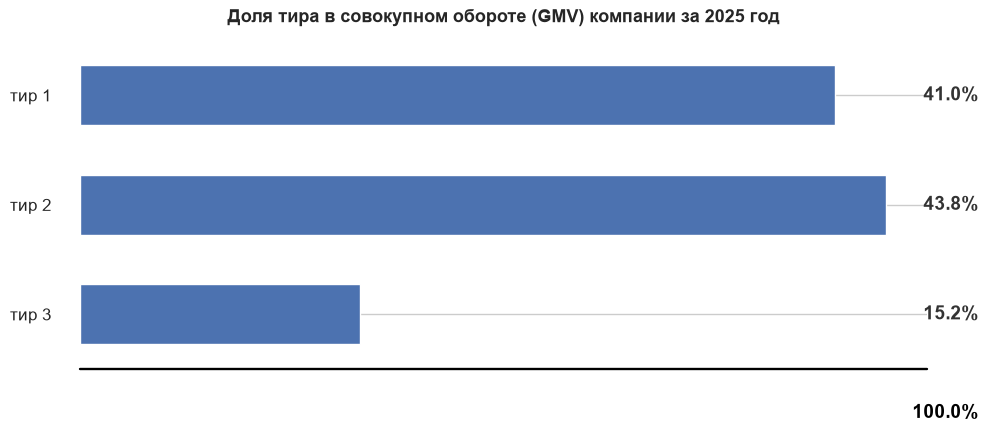

In [91]:
tiers_labels = ['тир 1', 'тир 2', 'тир 3']
shares = [41.0, 43.8, 15.2]


tiers_labels = tiers_labels[::-1]
shares = shares[::-1]

fig, ax = plt.subplots(figsize=(10, 4.5))


bars = ax.barh(tiers_labels, shares, color='#4C72B0', height=0.55)


x_pos = max(shares) + 5

for bar, share in zip(bars, shares):
    ax.text(
        x_pos,
        bar.get_y() + bar.get_height() / 2,
        f'{share:.1f}%',
        va='center',
        ha='right',  
        fontsize=14,
        fontweight='bold',
        color='#333333'
    )


ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.xaxis.set_visible(False)  


ax.tick_params(axis='y', left=False, labelsize=12, pad=15)


ax.axhline(y=-0.5, color="#000000", linewidth=1.7, clip_on=False)


ax.text(
    x_pos,
    -0.9,  
    '100.0%',
    va='center',
    ha='right',
    fontsize=14,
    fontweight='bold',
    color='#000000'
)


plt.title(
    'Доля тира в совокупном обороте (GMV) компании за 2025 год',
    fontsize=13,
    fontweight='bold',
    pad=20,
    loc='center'
)

plt.tight_layout()
plt.show()

Тип: горизонтальный бар-чарт

Разрез: GMV по тирам, % от общего оборота

Почему этот тип и разрез: Горизонтальные бары - лучший способ сравнить доли категорий(по мнению Александра Богачёва прочитанное мной в его руководстве по визуализации данных). Разрез по тирам выбран, потому что именно здесь скрыт контринтуитивный вывод: Tier 2 (43.8%) обгоняет Tier 1 (41.0%) по вкладу в выручку, хотя количество VIP-клиентов в Tier 1 всего 4. График наглядно показывает, что точечные "звёздные" клиенты не заменяют широкую базу.

Ключевая идея графика показать, что инвестировать в привлечение и удержание Tier 2 выгоднее, чем концентрироваться только на VIP-сегменте.

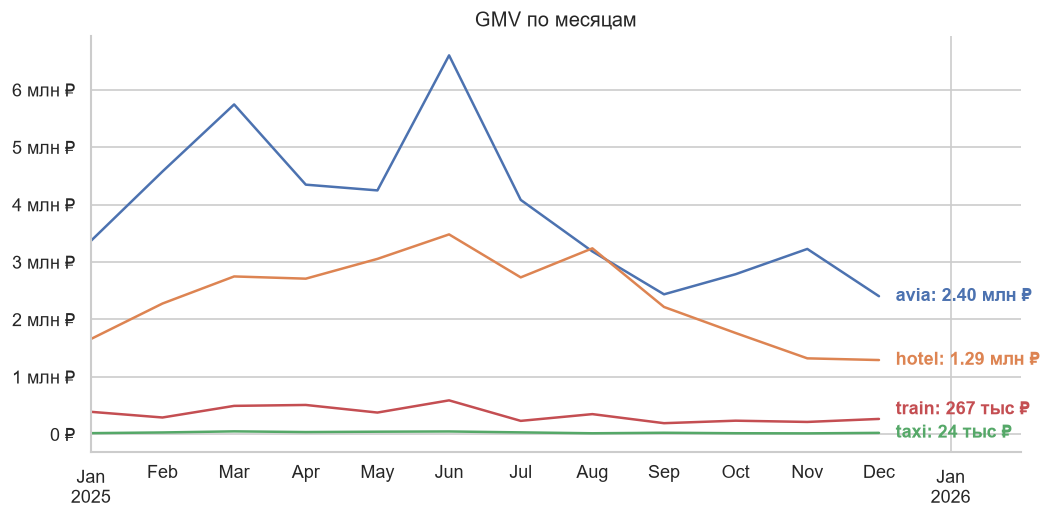

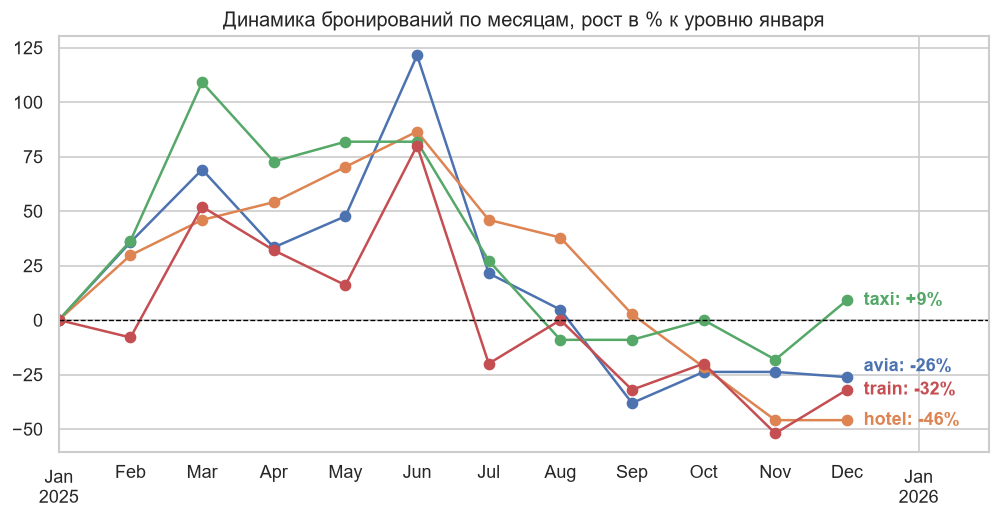

In [92]:
class RubFmt:
    def format(self, v):
        if v >= 1_000_000:
            return f'{v/1_000_000:.2f} млн ₽'
        elif v >= 1_000:
            return f'{v/1_000:.0f} тыс ₽'
        return f'{v:.0f} ₽'


def rub_formatter(x, pos):
    if x >= 1_000_000:
        return f'{x/1_000_000:g} млн ₽'
    elif x >= 1_000:
        return f'{x/1_000:g} тыс ₽'
    return f'{x:.0f} ₽'




def label_lines_at_end(ax, fmt='{:.0f}', x_pad_frac=0.18, fontsize=11, min_gap_pt=14):
    lines = [
        line for line in ax.get_lines()
        if len(line.get_xdata()) > 0 and not line.get_label().startswith('_')
    ]
    if not lines:
        return

    fig = ax.figure
    pt_to_px = fig.dpi / 72.0  

    entries = []
    for line in lines:
        xdata, ydata = line.get_xdata(), line.get_ydata()
        entries.append({
            'x': xdata[-1],
            'y': ydata[-1],
            'color': line.get_color(),
            'label': line.get_label()
        })


    points = np.array(
        [[ax.xaxis.convert_units(e['x']), e['y']] for e in entries],
        dtype=float
    )
    disp = ax.transData.transform(points)
    for e, (_, py) in zip(entries, disp):
        e['py'] = py

    entries.sort(key=lambda e: e['py'])
    min_gap_px = min_gap_pt * pt_to_px
    entries[0]['py_adj'] = entries[0]['py']
    for i in range(1, len(entries)):
        entries[i]['py_adj'] = max(entries[i]['py'], entries[i - 1]['py_adj'] + min_gap_px)

    for e in entries:
        dy_points = (e['py_adj'] - e['py']) / pt_to_px  # обратно в "точки" для annotate
        value_str = fmt.format(e['y']) if hasattr(fmt, 'format') else fmt.format(e['y'])
        ax.annotate(
            f"{e['label']}: {value_str}",
            xy=(e['x'], e['y']),
            xytext=(10, dy_points),
            textcoords='offset points',
            color=e['color'],
            fontweight='bold',
            fontsize=fontsize,
            va='center',
            annotation_clip=False
        )

    legend = ax.get_legend()
    if legend:
        legend.remove()
    xmin, xmax = ax.get_xlim()
    ax.set_xlim(xmin, xmax + (xmax - xmin) * x_pad_frac)



fig1, ax1 = plt.subplots(figsize=(10, 4.5), dpi=120)
pivot_gmv.plot(ax=ax1, legend=False, title='GMV по месяцам')
ax1.set_ylabel('')
ax1.set_xlabel('')
ax1.yaxis.set_major_formatter(FuncFormatter(rub_formatter))
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
label_lines_at_end(ax1, fmt=RubFmt())
plt.show()
plt.close(fig1)




fig3, ax3 = plt.subplots(figsize=(10, 4.5), dpi=120)
pivot_count_idx.plot(
    ax=ax3, legend=False, marker='o',
    title='Динамика бронирований по месяцам, рост в % к уровню января'
)
ax3.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax3.set_xlabel('')
label_lines_at_end(ax3, fmt='{:+.0f}%')
plt.show()
plt.close(fig3)

Тип: линейный график (линейная шкала)

Разрез: GMV в рублях по 4 субпродуктам, помесячно


Почему этот тип и разрез: Линия это стандарт для показа динамики во времени(снова ссылаюсь на профессиональное мнение Александра Богачёва), линейная шкала даёт бизнесу понятные абсолютные суммы. Разрез по субпродуктам показывает, что avia формирует основную форму годовой динамики компании.

Ключевой месседж бизнесу: Бизнес показал сильный рост в первом полугодии с пиком в июне, после чего последовал устойчивый спад до конца года практически во всех продуктах. Это не случайность и не аномалия одного месяца, этот спад напрямую связан с оттоком клиентов: 32% клиентов, активных в H1, полностью прекратили бронирования во втором полугодии, и на них приходилось 35% всего оборота H1. То есть спад GMV во втором полугодии это не сезонное затишье рынка, а результат конкретной проблемы удержания, которую можно и нужно решать в первую очередь.

Тип: линейный график (нормализованный, % роста)
Разрез: темп роста числа броней по 4 субпродуктам относительно января


Почему этот тип и разрез: Нормализация к январю убирает эффект масштаба и позволяет сравнить темп падения всех субпродуктов на одном графике, включая taxi с маленьким абсолютным объёмом.

Ключевой месседж бизнесу: Падение затронуло практически все субпродукты одновременно (avia, hotel, train  от -26% до -46% к декабрю), кроме taxi. Синхронность падения по разным продуктам это сильный аргумент в пользу того, что причина системная, а не специфичная для одного продукта. Это согласуется с гипотезой об оттоке: одни и те же клиенты бронировали разные субпродукты, и когда они ушли, просело всё сразу.

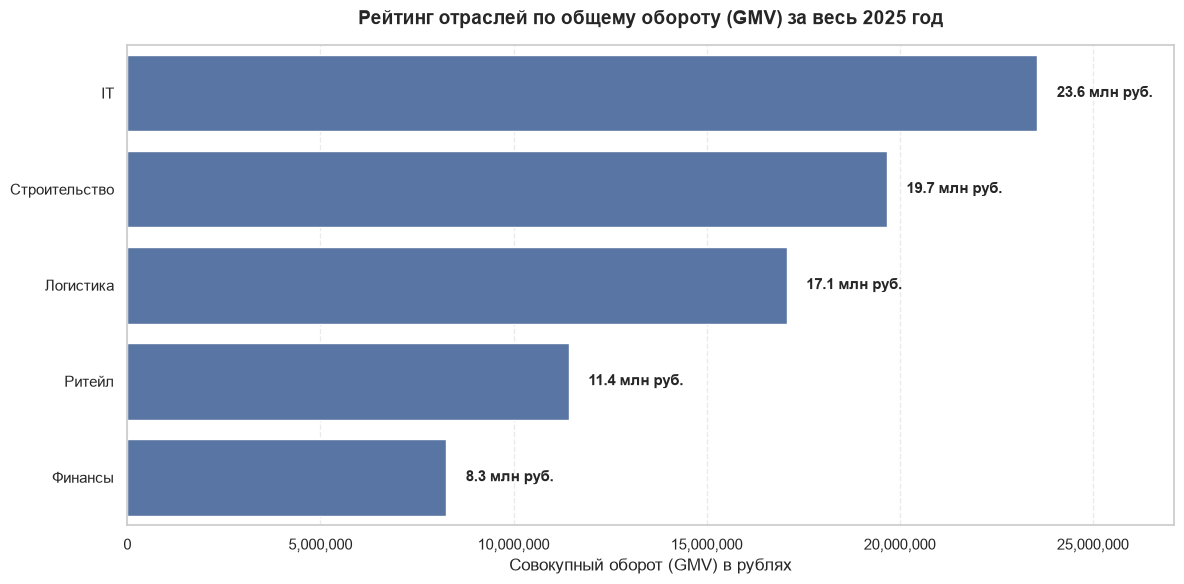

In [58]:
total_industry = bookings_clean[bookings_clean['status'] == 'confirmed'].merge(
    clients[['client_id', 'industry']], on='client_id', how='inner'
)

industry_year = (
    total_industry.groupby('industry')['amount_rub']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)


plt.figure(figsize=(12, 6))

sns.barplot(
    data=industry_year,
    x='amount_rub',
    y='industry'  
)


for index, row in industry_year.iterrows():
    plt.text(
        row['amount_rub'] + 500000,  
        index,
        f'{row['amount_rub']/1e6:.1f} млн руб.',
        va="center",
        fontsize=11,
        fontweight='bold'
    )


plt.title(
    'Рейтинг отраслей по общему обороту (GMV) за весь 2025 год',
    fontsize=14,
    fontweight='bold',
    pad=15
)
plt.xlabel('Совокупный оборот (GMV) в рублях', fontsize=12)

plt.ylabel('')

plt.xlim(0, industry_year['amount_rub'].max() * 1.15)


plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, loc: f"{int(x):,}")
)
plt.grid(True, linestyle="--", alpha=0.4, axis="x")
plt.tight_layout()
plt.show()

Тип: горизонтальный бар-чарт, отсортированный по убыванию

Разрез: GMV по отраслям клиентов

Почему этот тип и разрез: Ранжированный бар это лучший способ показать приоритет для отдела продаж: сразу видно, кто лидер и насколько разрыв велик между отраслями. Разрез именно по отрасли (а не по тиру) отвечает на вопрос "куда целиться на рынке?"  какие вертикали привлекать в первую очередь.

Ключевой месседж бизнесу: IT (23.6 млн) и Строительство (19.7 млн) наши приоритетные отрасли для таргетированного привлечения новых клиентов и допродаж действующим.

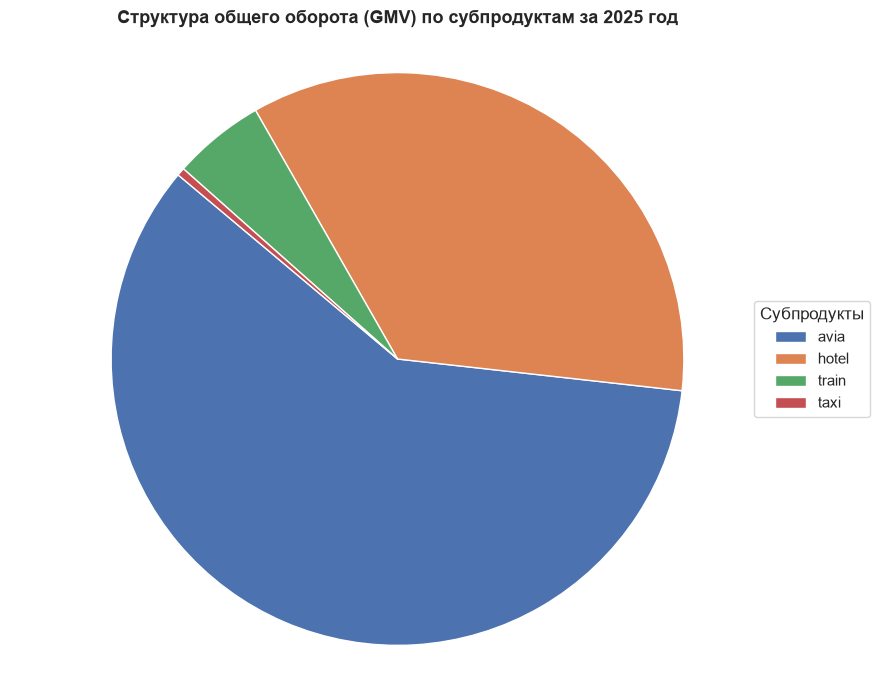

In [59]:
plt.figure(figsize=(9, 7))


wedges, texts = plt.pie(
    total_gmv_per_product["total_gmv"],
    startangle=140,
    colors=["#4C72B0", "#DD8452", "#55A868", "#C44E52"]
)


plt.legend(
    wedges,
    total_gmv_per_product["subproduct"],
    title="Субпродукты",
    loc="center left",
    bbox_to_anchor=(0.95, 0.5), 
    fontsize=11,
)


plt.title(
    "Структура общего оборота (GMV) по субпродуктам за 2025 год",
    fontsize=13,
    fontweight="bold",
    pad=15,
)

plt.axis("equal")
plt.tight_layout()
plt.show()

Тип: круговая диаграмма (pie chart)

Разрез: доля каждого субпродукта в годовом обороте

Почему этот тип и разрез: В отличие от остальных графиков (динамика, ранжирование), здесь задача была показать состав целого одним взглядом на управленческом слайде верхнего уровня, без привязки ко времени. Pie chart уместен именно потому, что категорий немного и разница между долями большая, следовательно восприятие "avia = больше половины бизнеса" считывается мгновенно.

Ключевой месседж бизнесу: Компания сильно зависит от одного субпродукта (59.3% GMV) и это точка роста (масштабировать успешную модель), и риск концентрации (нужна стратегия диверсификации в hotel/train, если avia замедлится).

### Блок 5 — Выводы 

**Задание 8.** Напиши 3–5 ключевых наблюдений из всего анализа. Для каждого сформулируй по структуре:

- **Что вижу:** факт из данных
- **Почему важно:** бизнес-значение
- **Что дальше:** что ты бы предложил(-а) проверить или сделать

**1. Авиа - доминирующий продукт с выраженной летней сезонностью**

**Что вижу:** По итогам 2025 года avia формирует 59.3% годового GMV и остаётся лидером по числу броней. Пик активности приходится на июнь (по числу броней всех субпродуктов 221% от уровня января) по всем субпродуктам, после чего идёт устойчивое снижение к декабрю. Проверка показала, что июньский всплеск это не разовый эффект и он не связан с одним крупным клиентом (топ-1 клиент - лишь 10% GMV месяца).

 **Почему важно:** Продукт с более чем половиной оборота компании определяет общую финансовую динамику бизнеса. Если сезонный спад после июня не учитывать в планировании, возможны ошибки в прогнозах выручки, cash flow и загрузке команды поддержки/продаж.

**Что дальше:** Я бы предложил заложить сезонность avia в финансовое планирование и KPI на 2026 год; проверить, действует ли аналогичный паттерн в других субпродуктах и годах; продумать акции/стимулирование спроса на «низкий сезон» (август–декабрь).

**2. Сезонность это пока гипотеза и требует подтверждения на длинном горизонте**

**Что вижу:** Внутригодовая цикличность видна количественно, но проявляется неравномерно в разных метриках (GMV, число броней, средний чек), к примеру по числу броней сильнее всего колеблются train (CV 37.6%) и avia (CV 39.3%), а по деньгам - taxi (CV 41.1%) и train (CV 37.6%), и построена только на данных одного года, что недостаточно для обнаружения сезонности.

**Почему важно:** Принимать стратегические решения (бюджетирование, найм, маркетинговый календарь) на основе одного цикла рискованно, ведь можно спутать сезонность с разовыми рыночными факторами (акции, макроэкономика, состав клиентской базы в моменте).

**Что дальше:** Поэтому, чтобы проверить есть ли сезонность я предлагаю собрать и проанализировать данные минимум за 2-3 года, чтобы подтвердить устойчивость паттерна; при накоплении истории построить помесячный сезонный индекс для каждого субпродукта отдельно.

**3. Средний бизнес (Tier 2) наш главный источник выручки, а не крупные клиенты**

**Что вижу:** Tier 2 (16 компаний) совершил в 1.8 раза больше броней, чем Tier 3 (30 компаний): 787 против 424. 

Один сотрудник Tier 2 бронирует в 3.5 раза чаще сотрудника Tier 3 (49.2 против 14.1 в год), а средний годовой оборот на сотрудника Tier 2 - 2.22 млн руб., против 430 тыс. у Tier 3. 

Несмотря на то, что отдельные VIP-клиенты Tier 1 показывают рекордные метрики на человека, суммарный GMV Tier 2 (35.0 млн руб.) превысил GMV Tier 1 (32.8 млн руб.), просто потому что клиентов Tier 1 критически мало (всего 4).

**Почему важно:** Компания зависит от диверсифицированной базы среднего бизнеса больше, чем принято думать, ориентируясь на VIP-логику «главное - крупные клиенты». Ставка только на Tier 1 делает выручку хрупкой из-за малого числа аккаунтов.

**Что дальше:** Выделить Tier 2 в отдельный приоритетный сегмент для удержания и роста (отдельный аккаунт-менеджмент, программы лояльности); проверить unit-экономику по привлечению клиентов Tier 2 vs Tier 1, чтобы понять, куда эффективнее вкладывать бюджет на рост.

**4. Высокий отток во втором полугодии, сконцентрированный в нескольких аккаунтах**

**Что вижу:** 32% клиентов (16 из 50), активных в H1 2025, не сделали ни одного оплаченного бронирования в H2. Их H1 GMV - 16.77 млн руб. (35.2% от общего H1 GMV), причём 42.2% этой суммы приходится всего на 3 компании (СтандартХолд, МегаСтрой, АтлантТрейд).

**Почему важно:** Отток такого масштаба во втором полугодии сильно бьёт по годовой выручке; концентрация риска в узком круге клиентов означает, что потеря/удержание буквально нескольких аккаунтов сильно влияет на итоговые показатели компании.

**Что дальше:** Здесь нужно разобраться в чём причины ухода топ-3 «ушедших» клиентов (сервис, цена, конкуренты, внутренние изменения у клиента) и постввить эту задачу во первый приоритет по решению, иначе вкладывание денег в рост GMV будет напрасным ведь мы не знаем почему от нас уходят; настроить автоматический алерт на отсутствие активности за N дней для проактивного удержания.

**5. Риск оттока по деньгам сосредоточен в Tier 2, а не в Tier 1 или Tier 3**

**Что вижу:** Churn rate: 0% в Tier 1 (0 из 4), 37.5% в Tier 2 (6 из 16), 33.3% в Tier 3 (10 из 30) - разница между Tier 2 и Tier 3 в пределах статистической погрешности при такой выборке. Но по деньгам разрыв критичен: 6 ушедших клиентов Tier 2 унесли 12.65 млн руб. (76% всего churn-GMV), тогда как 10 клиентов Tier 3 - только 4.12 млн руб.

**Почему важно:** Учитывая, что Tier 2 это ключевой источник выручки (см. пункт 3), отток именно в этом сегменте наносит наибольший финансовый удар и одновременно противоречит выводу о том, что Tier 2 это самый ценный сегмент для роста.

**Что дальше:** Запустить прицельную retention-программу для Tier 2 (персональный аккаунтинг, ранние сигналы снижения активности, whin-back предложения); проверить, есть ли общие признаки (отрасль, каналы привлечения, менеджер) у 6 ушедших клиентов Tier 2, чтобы выявить системную причину.